# LAB 08 — Thực nghiệm 14–22



In [28]:
# Nếu thiếu thư viện, cài trong môi trường notebook trước khi chạy:
# %pip install torch transformers pandas numpy scikit-learn matplotlib seaborn kagglehub
from pathlib import Path
import json, random, time, copy, zipfile, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from transformers import AutoTokenizer, AutoConfig, AutoModel, get_linear_schedule_with_warmup
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm
from pretrained_classification import PretrainedClassificationHead

SEED = 2026
MODEL_NAME = 'prajjwal1/bert-tiny'  # compact BERT: much faster for repeated controlled experiments
# Prefer a complete standard-cache snapshot. Old/incomplete Windows snapshots may
# point at files that were never created because symlink permission was missing.
MODEL_LOCAL_DIR = Path.home() / '.cache' / 'nlp_lab08_models' / 'bert-tiny'

def checkpoint_is_complete(path):
    path = Path(path)
    has_config = (path / 'config.json').is_file()
    has_tokenizer = any((path / name).is_file() for name in ('vocab.txt', 'tokenizer.json', 'spiece.model'))
    has_weights = any((path / name).is_file() for name in ('pytorch_model.bin', 'model.safetensors'))
    return has_config and has_tokenizer and has_weights

if checkpoint_is_complete(MODEL_LOCAL_DIR):
    MODEL_DIR = str(MODEL_LOCAL_DIR)
    print(f'Using complete Windows-safe checkpoint: {MODEL_DIR}')
else:
    try:
        cached_dir = snapshot_download(MODEL_NAME, local_files_only=True)
        if not checkpoint_is_complete(cached_dir):
            raise FileNotFoundError(f'Incomplete Hugging Face snapshot: {cached_dir}')
        MODEL_DIR = str(cached_dir)
        print(f'Using complete cached checkpoint: {MODEL_DIR}')
    except Exception as cache_error:
        print(f'No complete cached checkpoint ({cache_error}); downloading to {MODEL_LOCAL_DIR} as regular files...')
        MODEL_LOCAL_DIR.mkdir(parents=True, exist_ok=True)
        try:
            MODEL_DIR = snapshot_download(
                MODEL_NAME, local_dir=str(MODEL_LOCAL_DIR), local_dir_use_symlinks=False
            )
        except TypeError:  # newer huggingface_hub releases removed this deprecated option
            MODEL_DIR = snapshot_download(MODEL_NAME, local_dir=str(MODEL_LOCAL_DIR))
        MODEL_DIR = str(MODEL_DIR)
        if not checkpoint_is_complete(MODEL_DIR):
            raise RuntimeError(
                f'Download finished without a complete model at {MODEL_DIR}. '
                'Check Hugging Face network/SSL access, then rerun this cell.'
            )
HF_LOCAL_ONLY = True
MAX_LENGTHS = [64, 128, 256]
FAST_CPU_MODE = not torch.cuda.is_available()  # Set False manually to run full splits on CPU.
EPOCHS = 10
SWEEP_EPOCHS = 10  # data-size and sequence-length sweeps
BATCH_SIZE = 16 if FAST_CPU_MODE else 32
CPU_TRAIN_LIMIT = 2400 if FAST_CPU_MODE else None
CPU_VALID_LIMIT = 800 if FAST_CPU_MODE else None
CPU_TEST_LIMIT = 800 if FAST_CPU_MODE else None
LR = 2e-5
FROZEN_LR = 1e-3  # the frozen encoder only trains the small classification head
AMAZON_MAX_PER_CLASS = 20000  # deterministic cap for manageable experiments
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
AMP_DTYPE = torch.float16 if USE_AMP else torch.bfloat16
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
print(f'Device: {DEVICE} | model: {MODEL_NAME} | AMP: {USE_AMP} | fast CPU profile: {FAST_CPU_MODE} | core epochs: {EPOCHS} | sweep epochs: {SWEEP_EPOCHS}')

Using complete Windows-safe checkpoint: C:\Users\User\.cache\nlp_lab08_models\bert-tiny
Device: cpu | model: prajjwal1/bert-tiny | AMP: False | fast CPU profile: True | core epochs: 10 | sweep epochs: 10


<!-- codex-analysis-ft-setup -->
### Nhận xét về cấu hình chạy

Notebook dùng `prajjwal1/bert-tiny` trên CPU, không bật AMP; cấu hình thực nghiệm chính chạy 10 epoch và các lượt quét dữ liệu chạy 1 epoch. Các thời gian trong notebook vì vậy là thời gian CPU của cấu hình này, không đại diện cho tốc độ khi chạy GPU. IMDb/Amazon ở các thí nghiệm phân loại phía dưới được giới hạn tối đa 2.400 mẫu train, 800 validation và 800 test mỗi bộ để giảm thời gian chạy.


IMDb archive: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip
Using cached Kaggle dataset: C:\Users\User\.cache\kagglehub\datasets\kritanjalijain\amazon-reviews\versions\2
Amazon sampled reviews: negative=20,000, positive=20,000


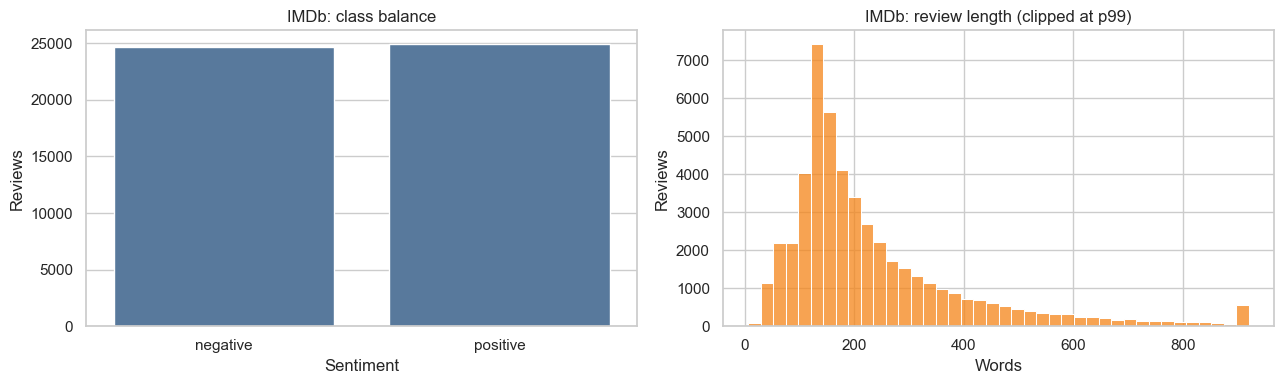

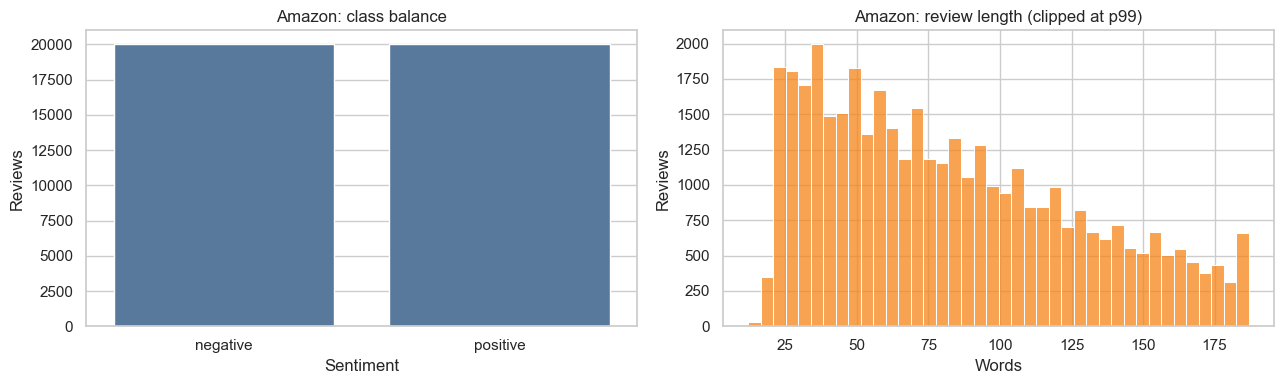

,dataset,rows,unique_reviews,negative,positive,mean_words,median_words,p95_words,max_words
0,IMDb,49581,49581,24697,24884,235.704141,177.0,601.0,2505
1,Amazon,40000,40000,20000,20000,82.647850,74.0,167.0,218


c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


IMDb: mean subword tokens=291.7, p95=725
Amazon: mean subword tokens=101.9, p95=206


In [14]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def normalize_reviews(texts, labels, domain):
    frame = pd.DataFrame({'text': texts, 'label': labels}).dropna(subset=['text','label'])
    frame['text'] = frame.text.astype(str).str.replace(r'<br\s*/?>',' ',regex=True).str.strip()
    frame['label'] = pd.to_numeric(frame.label,errors='coerce')
    frame = frame.dropna(subset=['label']); frame['label'] = frame.label.astype(int)
    frame = frame[(frame.text.str.len()>0) & frame.label.isin([0,1])].drop_duplicates('text').reset_index(drop=True)
    frame['domain'] = domain
    if frame.empty: raise ValueError(f'No usable labeled examples for {domain}')
    return frame

def load_imdb(zip_path):
    with zipfile.ZipFile(zip_path) as archive:
        csv_name = next(n for n in archive.namelist() if n.lower().endswith('.csv'))
        raw = pd.read_csv(archive.open(csv_name))
    cols = {str(c).lower():c for c in raw.columns}
    sentiment = raw[cols['sentiment']].astype(str).str.lower().map({'negative':0,'positive':1})
    return normalize_reviews(raw[cols['review']],sentiment,'IMDb')

def load_amazon_kaggle(max_per_class=AMAZON_MAX_PER_CLASS):
    import kagglehub
    versions_dir=Path.home()/'.cache'/'kagglehub'/'datasets'/'kritanjalijain'/'amazon-reviews'/'versions'
    cached_versions=sorted([p for p in versions_dir.iterdir() if p.is_dir()],key=lambda p:int(p.name) if p.name.isdigit() else -1) if versions_dir.exists() else []
    cached_root=next((p for p in reversed(cached_versions) if list(p.rglob('*.csv'))),None)
    if cached_root is not None:
        root=cached_root; print(f'Using cached Kaggle dataset: {root}')
    else:
        try:
            root=Path(kagglehub.dataset_download('kritanjalijain/amazon-reviews'))
        except Exception as exc:
            raise RuntimeError('KaggleHub download failed and no cached dataset exists. Check Kaggle access and SSL certificates.') from exc
    files = sorted([*root.rglob('*.csv'),*root.rglob('*.json'),*root.rglob('*.jsonl')])
    if not files: raise FileNotFoundError(f'No tabular review data found under {root}')
    collected={0:[],1:[]}; seen=set()
    text_names=['review','reviewtext','review_text','text','content','description','review_title']
    rating_names=['overall','rating','score','stars','star_rating','reviews.rating']
    label_names=['class_index','label','sentiment','polarity']
    for file in files:
        try:
            if file.suffix.lower()!='.csv': continue
            header=pd.read_csv(file,nrows=0).columns
            lower={str(c).strip().lower():c for c in header}
            txt=next((lower[n] for n in text_names if n in lower),None)
            rating=next((lower[n] for n in rating_names if n in lower),None)
            label_col=next((lower[n] for n in label_names if n in lower),None)
            if txt is None and label_col is None:
                probe=pd.read_csv(file,header=None,nrows=3)
                looks_headerless=(probe.shape[1]>=3 and pd.to_numeric(probe.iloc[:,0],errors='coerce').isin([1,2]).all())
                if not looks_headerless: continue
                names=['class_index','title','content'] if probe.shape[1]==3 else ['class_index','title','content',*range(3,probe.shape[1])]
                for chunk in pd.read_csv(file,header=None,names=names,usecols=[0,1,2],chunksize=50000,low_memory=False):
                    raw_label=pd.to_numeric(chunk['class_index'],errors='coerce')
                    labels=raw_label.map({1:0,2:1}).fillna(-1).to_numpy()
                    texts=chunk['title'].fillna('').astype(str).str.strip()+' '+chunk['content'].fillna('').astype(str).str.strip()
                    for text,label in zip(texts,labels):
                        key=str(text).strip()
                        if label not in (0,1) or not key or key in seen or len(collected[label])>=max_per_class: continue
                        seen.add(key); collected[label].append(key)
                    if all(len(collected[k])>=max_per_class for k in (0,1)): break
                if all(len(collected[k])>=max_per_class for k in (0,1)): break
                continue
            if txt is None or (rating is None and label_col is None): continue
            usecols=list(dict.fromkeys([txt]+([rating] if rating else [])+([label_col] if label_col else [])))
            for chunk in pd.read_csv(file,usecols=usecols,chunksize=50000,low_memory=False):
                if label_col is not None:
                    raw_label=chunk[label_col].astype(str).str.strip().str.lower()
                    labels=raw_label.map({'negative':0,'neg':0,'0':0,'1':0,'positive':1,'pos':1,'2':1}).fillna(-1).to_numpy()
                else:
                    score=pd.to_numeric(chunk[rating],errors='coerce')
                    labels=np.where(score<=2,0,np.where(score>=4,1,-1))
                title_col=lower.get('title') or lower.get('review_title')
                texts=chunk[txt].fillna('').astype(str)
                if title_col is not None and title_col!=txt and title_col in chunk:
                    texts=chunk[title_col].fillna('').astype(str)+' '+texts
                for text,label in zip(texts,labels):
                    if label not in (0,1) or pd.isna(text) or len(collected[label])>=max_per_class: continue
                    key=str(text).strip()
                    if not key or key in seen: continue
                    seen.add(key); collected[label].append(key)
                if all(len(collected[k])>=max_per_class for k in (0,1)): break
        except Exception as exc:
            print(f'Skipping {file.name}: {exc}')
        if all(len(collected[k])>=max_per_class for k in (0,1)): break
    texts=collected[0]+collected[1]; labels=[0]*len(collected[0])+[1]*len(collected[1])
    if not texts: raise ValueError('Could not detect Amazon review text and rating columns.')
    print(f'Amazon sampled reviews: negative={len(collected[0]):,}, positive={len(collected[1]):,}')
    return normalize_reviews(texts,labels,'Amazon')

def split_602020(frame,seed=SEED):
    train,rest=train_test_split(frame,test_size=.4,random_state=seed,stratify=frame.label)
    valid,test=train_test_split(rest,test_size=.5,random_state=seed,stratify=rest.label)
    return tuple(x.reset_index(drop=True) for x in (train,valid,test))

def stats_table(frame,name):
    words=frame.text.str.findall(r'\b\w+\b').str.len()
    return {'dataset':name,'rows':len(frame),'unique_reviews':frame.text.nunique(),
            'negative':int((frame.label==0).sum()),'positive':int((frame.label==1).sum()),
            'mean_words':words.mean(),'median_words':words.median(),
            'p95_words':words.quantile(.95),'max_words':words.max()}

def plot_dataset_stats(datasets):
    sns.set_theme(style='whitegrid'); rows=[]
    for name,frame in datasets.items():
        rows.append(stats_table(frame,name)); words=frame.text.str.findall(r'\b\w+\b').str.len()
        fig,axes=plt.subplots(1,2,figsize=(13,4))
        sns.countplot(x=frame.label.map({0:'negative',1:'positive'}),order=['negative','positive'],ax=axes[0],color='#4c78a8')
        axes[0].set(title=f'{name}: class balance',xlabel='Sentiment',ylabel='Reviews')
        sns.histplot(words.clip(upper=words.quantile(.99)),bins=40,ax=axes[1],color='#f58518')
        axes[1].set(title=f'{name}: review length (clipped at p99)',xlabel='Words',ylabel='Reviews')
        fig.tight_layout(); plt.show()
    summary=pd.DataFrame(rows); display(summary); return summary

seed_everything()
# Colab: clone lab08 and upload/mount archive.zip, or set IMDB_ZIP_PATH explicitly.
IMDB_ZIP_CANDIDATES = [
    Path('../data/archive.zip'), Path('data/archive.zip'), Path('archive.zip'),
    Path('/content/archive.zip'), Path('/content/drive/MyDrive/archive.zip'),
    Path('/content/drive/MyDrive/data/archive.zip'),
    Path(r'D:/Study/Study_Class/Semester_7/NLP/Lab/data/archive.zip'),
]
IMDB_ZIP_PATH = next((p.resolve() for p in IMDB_ZIP_CANDIDATES if p.exists()), None)
if IMDB_ZIP_PATH is None:
    searched = '\n'.join(f'  - {p}' for p in IMDB_ZIP_CANDIDATES)
    raise FileNotFoundError('IMDb archive.zip was not found. Upload it to Colab or mount Drive. Checked:\n' + searched)
print('IMDb archive:', IMDB_ZIP_PATH)
imdb=load_imdb(IMDB_ZIP_PATH)
amazon=load_amazon_kaggle()
datasets={'IMDb':imdb,'Amazon':amazon}
dataset_summary=plot_dataset_stats(datasets)
if not checkpoint_is_complete(MODEL_DIR):
    raise FileNotFoundError(f'Model checkpoint is incomplete: {MODEL_DIR}. Rerun the setup cell.')
tokenizer=AutoTokenizer.from_pretrained(str(MODEL_DIR),local_files_only=True)
for name,frame in datasets.items():
    sample=frame.text.sample(min(2000,len(frame)),random_state=SEED).tolist()
    lengths=[len(ids) for ids in tokenizer(sample,truncation=False)['input_ids']]
    print(f'{name}: mean subword tokens={np.mean(lengths):.1f}, p95={np.quantile(lengths,.95):.0f}')

<!-- codex-analysis-ft-data -->
### Nhận xét về thống kê dữ liệu

IMDb có 49.581 review duy nhất, gồm 24.697 negative và 24.884 positive; Amazon có 40.000 review, cân bằng chính xác 20.000 mỗi lớp. Trung bình review IMDb dài 235,7 từ, median 177 và p95 là 601 từ; Amazon ngắn hơn rõ rệt với trung bình 82,6, median 74 và p95 là 167 từ. Vì vậy hai nguồn có độ dài và cách diễn đạt khác nhau đáng kể, phù hợp để khảo sát domain shift. Với BERT-Tiny, mẫu thống kê có trung bình 291,7 subword cho IMDb và 101,9 cho Amazon; các con số này là token hóa của model, không phải số từ.


## 14. Experiment 1 — Pretrained vs From Scratch
Sau khi tự điền prediction, so sánh cùng split, tokenizer, sequence length, epochs và head; khác biệt chính là encoder weights pretrained hay khởi tạo ngẫu nhiên.

In [15]:
# Shared utilities used by each experiment below. Test is evaluated only after validation checkpoint selection.
class ReviewDataset(Dataset):
    def __init__(self,frame,tok,max_length):
        self.labels=torch.as_tensor(frame.label.astype(int).to_numpy(),dtype=torch.long)
        # Tokenize once per dataset, not once per review per epoch.
        self.encoded=tok(frame.text.tolist(),max_length=max_length,truncation=True,padding='max_length',return_tensors='pt')
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        return {k:v[i] for k,v in self.encoded.items()} | {'labels':self.labels[i]}

TOKENIZED_DATASETS = {}  # bounded CPU cache, reused across experiments with the same split/length
TOKEN_CACHE_LIMIT = 6

def get_review_dataset(frame, max_length):
    key=(id(frame),max_length)
    cached=TOKENIZED_DATASETS.get(key)
    if cached is not None and cached[0] is frame:
        return cached[1]
    dataset=ReviewDataset(frame,tokenizer,max_length)
    TOKENIZED_DATASETS[key]=(frame,dataset)  # retain frame to prevent id reuse
    while len(TOKENIZED_DATASETS)>TOKEN_CACHE_LIMIT:
        TOKENIZED_DATASETS.pop(next(iter(TOKENIZED_DATASETS)))
    return dataset

def evaluate_model(model,loader):
    model.eval(); ys=[]; preds=[]; confs=[]; pos_probs=[]; losses=[]
    with torch.no_grad():
        for batch in loader:
            batch={k:v.to(DEVICE, non_blocking=USE_AMP) for k,v in batch.items()}
            labels=batch.pop('labels')
            with torch.autocast(device_type=DEVICE.type,dtype=AMP_DTYPE,enabled=USE_AMP):
                logits=model(**batch); loss=nn.functional.cross_entropy(logits,labels)
            losses.append(loss.item())
            probs=logits.float().softmax(-1); conf,pred=probs.max(-1)
            ys.extend(labels.cpu().tolist()); preds.extend(pred.cpu().tolist()); confs.extend(conf.cpu().tolist()); pos_probs.extend(probs[:,1].cpu().tolist())
    metrics={'loss':float(np.mean(losses)),'accuracy':accuracy_score(ys,preds),
             'precision':precision_score(ys,preds,zero_division=0),'recall':recall_score(ys,preds,zero_division=0),
             'f1':f1_score(ys,preds,zero_division=0),'roc_auc':roc_auc_score(ys,pos_probs),
             'confusion_matrix':confusion_matrix(ys,preds,labels=[0,1]).tolist()}
    return metrics,np.asarray(ys),np.asarray(preds),np.asarray(confs),np.asarray(pos_probs)

def create_classifier(pretrained=True):
    if pretrained: return PretrainedClassificationHead(MODEL_DIR,local_files_only=HF_LOCAL_ONLY)
    config=AutoConfig.from_pretrained(MODEL_DIR,local_files_only=HF_LOCAL_ONLY)
    random_encoder=AutoModel.from_config(config)
    return PretrainedClassificationHead(MODEL_DIR,encoder=random_encoder,local_files_only=HF_LOCAL_ONLY)

def run_experiment(name,train_df,valid_df,test_df,*,pretrained=True,frozen=False,max_length=128,epochs=EPOCHS):
    seed_everything(SEED); print(f'\n{name}: initializing {"pretrained" if pretrained else "from-scratch"} model',flush=True); model=create_classifier(pretrained)
    if frozen:
        for parameter in model.encoder.parameters(): parameter.requires_grad=False
    model.to(DEVICE)
    make_loader=lambda df,shuffle=False:DataLoader(get_review_dataset(df,max_length),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0,pin_memory=USE_AMP)
    train_loader=make_loader(train_df,True); valid_loader=make_loader(valid_df); test_loader=make_loader(test_df)
    learning_rate=FROZEN_LR if frozen else LR
    optimizer=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=learning_rate)
    try:
        scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    except (AttributeError,TypeError):
        scaler=torch.cuda.amp.GradScaler(enabled=USE_AMP)
    total_steps=max(1,len(train_loader)*epochs); scheduler=get_linear_schedule_with_warmup(optimizer,int(.1*total_steps),total_steps)
    best_f1=-1; best_weights=None; history=[]; start=time.time()
    for epoch in range(epochs):
        model.train(); train_losses=[]
        progress=tqdm(train_loader,desc=f'{name} epoch {epoch+1}/{epochs}',leave=True)
        for batch in progress:
            batch={k:v.to(DEVICE,non_blocking=USE_AMP) for k,v in batch.items()}; labels=batch.pop('labels')
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type,dtype=AMP_DTYPE,enabled=USE_AMP):
                logits=model(**batch); loss=nn.functional.cross_entropy(logits,labels)
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update(); scheduler.step(); train_losses.append(loss.item())
        valid_metrics,*_=evaluate_model(model,valid_loader)
        history.append({'epoch':epoch+1,'train_loss':float(np.mean(train_losses)),**valid_metrics})
        if valid_metrics['f1']>best_f1:
            best_f1=valid_metrics['f1']; best_weights=copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
        print(f'{name} | epoch {epoch+1}/{epochs} | train_loss={np.mean(train_losses):.4f} | val_F1={valid_metrics["f1"]:.4f}')
    model.load_state_dict(best_weights); model.to(DEVICE)
    test_metrics,y,pred,conf,pos=evaluate_model(model,test_loader); elapsed=time.time()-start
    predictions=pd.DataFrame({'text':test_df.text.tolist(),'true_label':y,'prediction':pred,'confidence':conf,'positive_probability':pos})
    row={'experiment':name,'accuracy':test_metrics['accuracy'],'precision':test_metrics['precision'],
         'recall':test_metrics['recall'],'f1':test_metrics['f1'],'roc_auc':test_metrics['roc_auc'],
         'test_loss':test_metrics['loss'],'training_seconds':elapsed,'max_length':max_length,
         'train_rows':len(train_df),'validation_rows':len(valid_df),'test_rows':len(test_df),
         'pretrained':pretrained,'frozen':frozen,'confusion_matrix':test_metrics['confusion_matrix']}
    return row,predictions,history

imdb_train,imdb_valid,imdb_test=split_602020(imdb)
amazon_train,amazon_valid,amazon_test=split_602020(amazon)
def stratified_cap(frame,limit):
    if limit is None or len(frame)<=limit: return frame.copy().reset_index(drop=True)
    kept,_=train_test_split(frame,train_size=limit,random_state=SEED,stratify=frame.label)
    return kept.reset_index(drop=True)
if FAST_CPU_MODE:
    imdb_train=stratified_cap(imdb_train,CPU_TRAIN_LIMIT); imdb_valid=stratified_cap(imdb_valid,CPU_VALID_LIMIT); imdb_test=stratified_cap(imdb_test,CPU_TEST_LIMIT)
    amazon_train=stratified_cap(amazon_train,CPU_TRAIN_LIMIT); amazon_valid=stratified_cap(amazon_valid,CPU_VALID_LIMIT); amazon_test=stratified_cap(amazon_test,CPU_TEST_LIMIT)
    print('Using stratified CPU subset caps:',CPU_TRAIN_LIMIT,CPU_VALID_LIMIT,CPU_TEST_LIMIT)
print('IMDb split:',len(imdb_train),len(imdb_valid),len(imdb_test))
print('Amazon split:',len(amazon_train),len(amazon_valid),len(amazon_test))
results=[]; prediction_sets={}; histories={}

Using stratified CPU subset caps: 2400 800 800
IMDb split: 2400 800 800
Amazon split: 2400 800 800


<!-- codex-analysis-ft-split -->
### Nhận xét về tập dùng trong huấn luyện

Mỗi dataset được chia stratified thành 2.400 train, 800 validation và 800 test, tương ứng 60/20/20 trên phần dữ liệu được lấy mẫu cho thí nghiệm. Nhãn được giữ cân bằng giữa các split. Kết quả bên dưới vì thế phản ánh cấu hình thử nghiệm rút gọn trên CPU, không phải huấn luyện trên toàn bộ 49.581 review IMDb hay 40.000 review Amazon.


In [16]:
# Train both initializations with all other settings fixed.
for name,pretrained in [('14_pretrained',True),('14_from_scratch',False)]:
    row,preds,hist=run_experiment(name,imdb_train,imdb_valid,imdb_test,pretrained=pretrained)
    results.append(row); prediction_sets[name]=preds; histories[name]=hist
display(pd.DataFrame(results).query("experiment.str.startswith('14_')",engine='python')[['experiment','accuracy','f1','training_seconds']].round(4))


14_pretrained: initializing pretrained model


14_pretrained epoch 1/10:   0%|          | 0/150 [00:00<?, ?it/s]

14_pretrained | epoch 1/10 | train_loss=0.7024 | val_F1=0.6027


14_pretrained epoch 2/10:   0%|          | 0/150 [00:00<?, ?it/s]

14_pretrained | epoch 2/10 | train_loss=0.6535 | val_F1=0.6361


14_pretrained epoch 3/10:   0%|          | 0/150 [00:00<?, ?it/s]

... (32 outputs left out)

14_from_scratch | epoch 9/10 | train_loss=0.6968 | val_F1=0.6954


14_from_scratch epoch 10/10:   0%|          | 0/150 [00:00<?, ?it/s]

14_from_scratch | epoch 10/10 | train_loss=0.6876 | val_F1=0.6752


,experiment,accuracy,f1,training_seconds
0,14_pretrained,0.7325,0.7440,314.9447
1,14_from_scratch,0.5938,0.6902,303.1411


<!-- codex-analysis-ft-exp14 -->
### Trả lời Experiment 1 — Pretrained vs From Scratch

Quan sát: trên cùng 2.400 review train và 800 review test, pretrained đạt accuracy 0,7325 và F1 0,7440; model khởi tạo ngẫu nhiên đạt accuracy 0,5938 và F1 0,6902. Chênh lệch là 13,87 điểm phần trăm accuracy và 5,38 điểm F1 nghiêng về pretrained. ROC-AUC lần lượt là 0,8218 và 0,7085. Thời gian huấn luyện gần nhau: 314,9 giây với pretrained và 303,1 giây từ đầu.

Diễn giải: trong thiết lập này, pretrained cho khả năng phân biệt review tốt hơn rõ rệt mà không cần nhiều thời gian huấn luyện hơn. Model scratch có recall 0,9027 nhưng precision chỉ 0,5586, nghĩa là bắt được nhiều review positive nhưng đồng thời gán positive nhầm khá nhiều. Kết quả ủng hộ vai trò của biểu diễn đã học trước; nó không chứng minh mọi Transformer pretrained đều tốt hơn trong mọi dữ liệu hay cấu hình.


### 14.1. Training time and train/validation loss

Loss curves show optimization behavior; the time plot compares measured training duration for the two initializations.

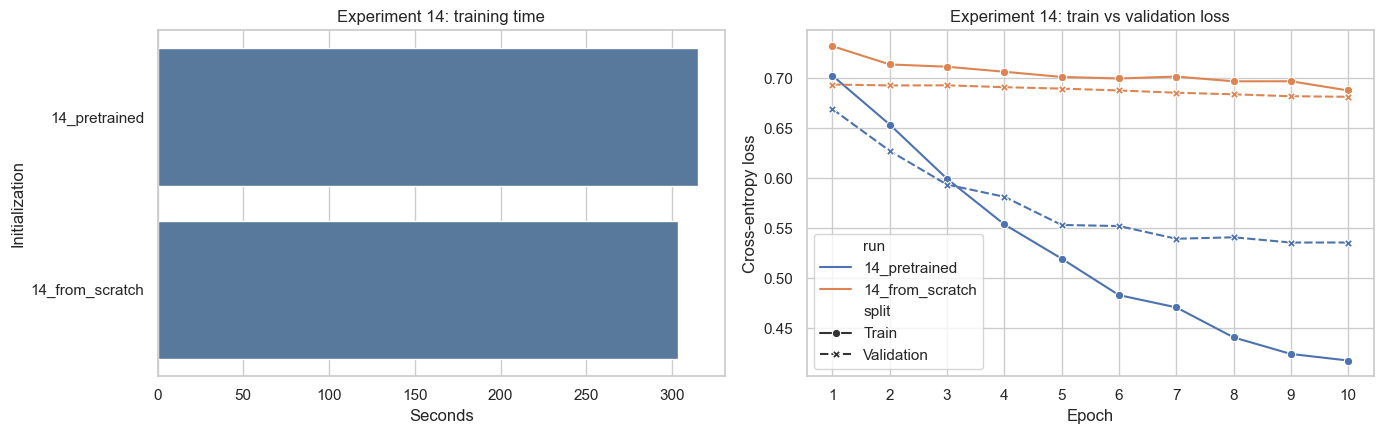

split                   Train  Validation
run             epoch                    
14_from_scratch 1      0.7318      0.6935
                2      0.7136      0.6926
                3      0.7113      0.6927
                4      0.7063      0.6909
                5      0.7011      0.6894
                6      0.6996      0.6876
                7      0.7014      0.6853
                8      0.6967      0.6837
                9      0.6968      0.6818
                10     0.6876      0.6813
14_pretrained   1      0.7024      0.6691
                2      0.6535      0.6273
                3      0.5994      0.5936
                4      0.5539      0.5814
                5      0.5197      0.5533
                6      0.4832      0.5522
                7      0.4710      0.5395
                8      0.4411      0.5410
                9      0.4245      0.5357
                10     0.4179      0.5358

In [17]:
exp14_names=['14_pretrained','14_from_scratch']
time14=pd.DataFrame([r for r in results if r['experiment'] in exp14_names])
curve_rows=[]
for run_name in exp14_names:
    for point in histories.get(run_name,[]):
        curve_rows.extend([
            {'run':run_name,'epoch':point['epoch'],'split':'Train','loss':point['train_loss']},
            {'run':run_name,'epoch':point['epoch'],'split':'Validation','loss':point['loss']},
        ])
curve14=pd.DataFrame(curve_rows)
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
sns.barplot(data=time14,x='training_seconds',y='experiment',color='#4c78a8',ax=axes[0])
axes[0].set(title='Experiment 14: training time',xlabel='Seconds',ylabel='Initialization')
sns.lineplot(data=curve14,x='epoch',y='loss',hue='run',style='split',markers=True,dashes=True,ax=axes[1])
axes[1].set(title='Experiment 14: train vs validation loss',xlabel='Epoch',ylabel='Cross-entropy loss',xticks=sorted(curve14.epoch.unique()))
plt.tight_layout(); plt.show()
display(curve14.pivot_table(index=['run','epoch'],columns='split',values='loss').round(4))


<!-- codex-analysis-ft-exp14-curves -->
### Đọc đường loss và thời gian của Experiment 1

Train loss pretrained giảm từ 0,7024 xuống 0,4179; validation loss giảm từ 0,6691 ở epoch 1 xuống thấp nhất khoảng 0,5357 ở epoch 9 rồi gần như giữ ở 0,5358. F1 validation cao nhất ở epoch 8 là 0,7538. Với model scratch, train loss chỉ giảm từ 0,7318 xuống 0,6876 và validation loss từ 0,6935 xuống 0,6813; F1 validation bằng 0 trong ba epoch đầu rồi đạt cao nhất 0,7079 ở epoch 6. Điều này cho thấy scratch học chậm hơn trong ngân sách 10 epoch đã dùng.

Khoảng cách train/validation loss cuối lượt pretrained lớn hơn scratch, nên có dấu hiệu model pretrained khớp tập train mạnh hơn; tuy nhiên validation F1 không sụt liên tục và test F1 vẫn cao hơn. Chỉ từ các đường này chưa thể kết luận quá khớp nghiêm trọng. Tổng thời gian ở biểu đồ cũng cho thấy lợi thế chất lượng của pretrained không đến từ việc chạy lâu hơn đáng kể.


## 15. Experiment 2 — Feature Extraction vs Fine-Tuning
Frozen mode updates only the task head; fine-tuning updates both encoder and head. The split and other settings remain fixed.

In [18]:
for name,frozen in [('15_feature_extraction',True),('15_fine_tuning',False)]:
    row,preds,hist=run_experiment(name,imdb_train,imdb_valid,imdb_test,pretrained=True,frozen=frozen)
    results.append(row); prediction_sets[name]=preds; histories[name]=hist
display(pd.DataFrame(results).query("experiment.str.startswith('15_')",engine='python'))


15_feature_extraction: initializing pretrained model


15_feature_extraction epoch 1/10:   0%|          | 0/150 [00:00<?, ?it/s]

15_feature_extraction | epoch 1/10 | train_loss=0.6915 | val_F1=0.6484


15_feature_extraction epoch 2/10:   0%|          | 0/150 [00:00<?, ?it/s]

15_feature_extraction | epoch 2/10 | train_loss=0.6256 | val_F1=0.6046


15_feature_extraction epoch 3/10:   0%|          | 0/150 [00:00<?, ?it/s]

... (32 outputs left out)

15_fine_tuning | epoch 9/10 | train_loss=0.4245 | val_F1=0.7509


15_fine_tuning epoch 10/10:   0%|          | 0/150 [00:00<?, ?it/s]

15_fine_tuning | epoch 10/10 | train_loss=0.4179 | val_F1=0.7488


,experiment,accuracy,precision,recall,f1,roc_auc,test_loss,training_seconds,max_length,train_rows,validation_rows,test_rows,pretrained,frozen,confusion_matrix
2,15_feature_extraction,0.68875,0.681818,0.710723,0.695971,0.767949,0.577913,75.172589,128,2400,800,800,True,True,"[[266, 133], [116, 285]]"
3,15_fine_tuning,0.73250,0.714943,0.775561,0.744019,0.821780,0.526080,225.323367,128,2400,800,800,True,False,"[[275, 124], [90, 311]]"


<!-- codex-analysis-ft-exp15 -->
### Trả lời Experiment 2 — Feature Extraction vs Fine-Tuning

Feature extraction đóng băng encoder đạt accuracy 0,6888, F1 0,6960 và ROC-AUC 0,7679; fine-tuning toàn bộ đạt lần lượt 0,7325, 0,7440 và 0,8218. Fine-tuning tăng 4,38 điểm phần trăm accuracy và 4,80 điểm F1. Đổi lại, thời gian tăng từ 75,2 lên 225,3 giây, xấp xỉ gấp 3 lần.

Ma trận nhầm lẫn cho thấy frozen model có 133 false positive và 116 false negative; fine-tuning có 124 false positive và 90 false negative. Cập nhật encoder giúp giảm cả hai loại lỗi trên tập test này, đặc biệt giảm 26 false negative. Kết quả gợi ý biểu diễn pretrained cần điều chỉnh để thích nghi tốt hơn với sentiment IMDb; frozen encoder vẫn là lựa chọn nhanh hơn khi tài nguyên hạn chế.


### 15.1. Runtime and learning curves

Compare frozen feature extraction with full fine-tuning, including validation loss.

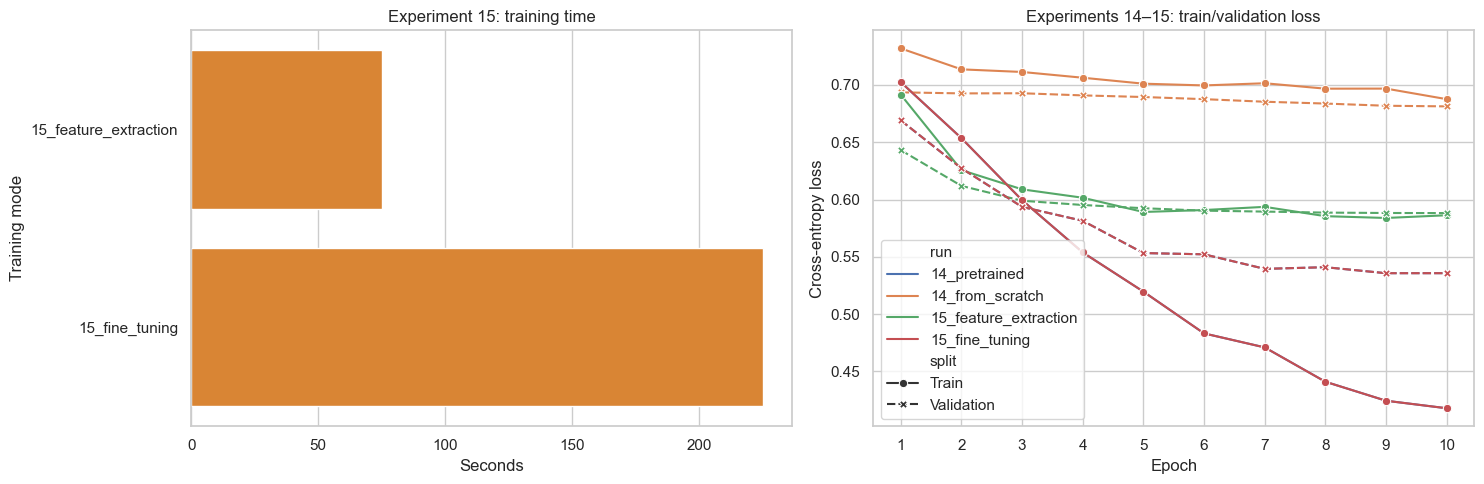

In [19]:
exp15_names=['15_feature_extraction','15_fine_tuning']
time15=pd.DataFrame([r for r in results if r['experiment'] in exp15_names])
curve_rows=[]
for run_name in exp14_names+exp15_names:
    for point in histories.get(run_name,[]):
        curve_rows.extend([
            {'run':run_name,'epoch':point['epoch'],'split':'Train','loss':point['train_loss']},
            {'run':run_name,'epoch':point['epoch'],'split':'Validation','loss':point['loss']},
        ])
main_curves=pd.DataFrame(curve_rows)
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=time15,x='training_seconds',y='experiment',color='#f58518',ax=axes[0])
axes[0].set(title='Experiment 15: training time',xlabel='Seconds',ylabel='Training mode')
sns.lineplot(data=main_curves,x='epoch',y='loss',hue='run',style='split',markers=True,dashes=True,ax=axes[1])
axes[1].set(title='Experiments 14–15: train/validation loss',xlabel='Epoch',ylabel='Cross-entropy loss',xticks=sorted(main_curves.epoch.unique()))
plt.tight_layout(); plt.show()


<!-- codex-analysis-ft-exp15-curves -->
### Đọc đường học của Feature Extraction và Fine-Tuning

Ở feature extraction, validation F1 dao động, đạt đỉnh 0,6975 tại epoch 4 rồi kết thúc ở 0,6684; train loss cuối là 0,5863. Khi fine-tune, validation F1 tăng lên đỉnh 0,7538 tại epoch 8, còn train loss giảm từ 0,7024 xuống 0,4179. Cùng với test F1 0,7440 so với 0,6960 của frozen model, các đường cong củng cố kết quả rằng cập nhật encoder đem lại chất lượng cao hơn trong bài toán này. Đổi lại, đường train loss giảm sâu hơn và thời gian huấn luyện dài hơn; nên chọn checkpoint theo validation, không chỉ theo train loss.


## 16. Experiment 3 — Amount of Training Data
Train subsets are sampled from the training split only. Validation and test frames are held constant across all four runs.


16_train_10pct: initializing pretrained model


16_train_10pct epoch 1/1:   0%|          | 0/15 [00:00<?, ?it/s]

16_train_10pct | epoch 1/1 | train_loss=0.7319 | val_F1=0.5778

16_train_25pct: initializing pretrained model


16_train_25pct epoch 1/1:   0%|          | 0/38 [00:00<?, ?it/s]

16_train_25pct | epoch 1/1 | train_loss=0.7235 | val_F1=0.5310

16_train_50pct: initializing pretrained model


16_train_50pct epoch 1/1:   0%|          | 0/75 [00:00<?, ?it/s]

16_train_50pct | epoch 1/1 | train_loss=0.7001 | val_F1=0.5707

16_train_100pct: initializing pretrained model


16_train_100pct epoch 1/1:   0%|          | 0/150 [00:00<?, ?it/s]

16_train_100pct | epoch 1/1 | train_loss=0.6882 | val_F1=0.5993


,experiment,train_rows,accuracy,f1,training_seconds
4,16_train_10pct,240,0.5325,0.5779,4.0758
5,16_train_25pct,600,0.5512,0.4979,7.0391
6,16_train_50pct,1200,0.5688,0.5735,15.2098
7,16_train_100pct,2400,0.5875,0.5635,27.2086


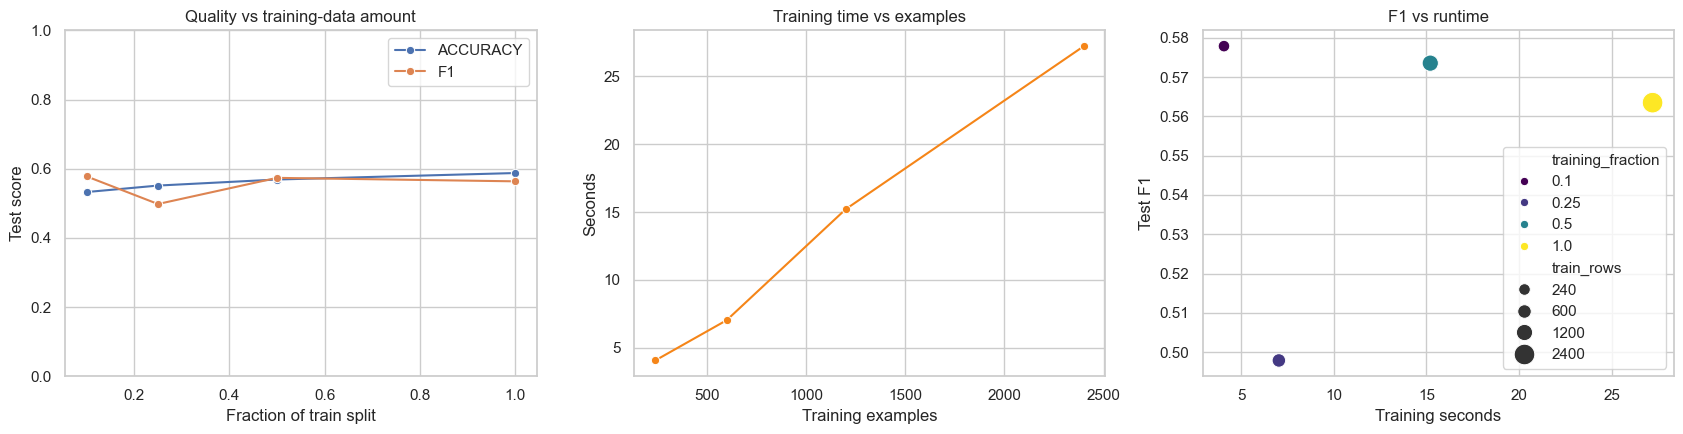

In [20]:
def stratified_fraction(frame,fraction):
    if fraction>=1: return frame.copy().reset_index(drop=True)
    subset,_=train_test_split(frame,test_size=1-fraction,random_state=SEED,stratify=frame.label)
    return subset.reset_index(drop=True)

for fraction in (.10,.25,.50,1.0):
    name=f'16_train_{int(fraction*100)}pct'; subset=stratified_fraction(imdb_train,fraction)
    row,preds,hist=run_experiment(name,subset,imdb_valid,imdb_test,pretrained=True,epochs=SWEEP_EPOCHS)
    row['training_fraction']=fraction; results.append(row); prediction_sets[name]=preds; histories[name]=hist
data_fraction_results=pd.DataFrame(results).query("experiment.str.startswith('16_')",engine='python')
display(data_fraction_results[['experiment','train_rows','accuracy','f1','training_seconds']].round(4))
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for metric in ['accuracy','f1']:
    sns.lineplot(data=data_fraction_results,x='training_fraction',y=metric,marker='o',label=metric.upper(),ax=axes[0])
axes[0].set(title='Quality vs training-data amount',xlabel='Fraction of train split',ylabel='Test score',ylim=(0,1))
sns.lineplot(data=data_fraction_results,x='train_rows',y='training_seconds',marker='o',ax=axes[1],color='#f58518')
axes[1].set(title='Training time vs examples',xlabel='Training examples',ylabel='Seconds')
sns.scatterplot(data=data_fraction_results,x='training_seconds',y='f1',hue='training_fraction',size='train_rows',sizes=(70,220),ax=axes[2],palette='viridis')
axes[2].set(title='F1 vs runtime',xlabel='Training seconds',ylabel='Test F1')
plt.tight_layout(); plt.show()


<!-- codex-analysis-ft-exp16 -->
### Trả lời Experiment 3 — Amount of Training Data

Các lượt này chỉ huấn luyện pretrained trong 1 epoch, với lần lượt 240, 600, 1.200 và 2.400 review. Accuracy tăng tương đối đều từ 0,5325 lên 0,5512, 0,5688 và 0,5875; ROC-AUC cũng tăng từ 0,5493 lên 0,6395. F1 không tăng đều: 0,5779 ở 10%, giảm còn 0,4979 ở 25%, rồi đạt 0,5735 ở 50% và 0,5635 ở 100%. Thời gian tăng từ 4,1 lên 27,2 giây.

Diễn giải: thêm dữ liệu giúp accuracy và ROC-AUC cải thiện trong lượt quét này, nhưng F1 dao động đáng kể. Mỗi cấu hình chỉ chạy một epoch nên chưa đo hiệu năng sau khi hội tụ. Hơn nữa, thí nghiệm không chạy các mức 10–100% cho model scratch; vì vậy output này chưa đủ để kết luận trực tiếp model nào giảm performance mạnh hơn khi ít dữ liệu. Muốn trả lời so sánh đó cần chạy cả pretrained và scratch trên cùng các tỷ lệ dữ liệu, cùng số epoch và split.


## 17. Experiment 4 — Maximum Sequence Length
Compare 64, 128 and 256 tokens with the same IMDb split and training configuration. The plot includes quality and runtime.


17_max_length_64: initializing pretrained model


17_max_length_64 epoch 1/10:   0%|          | 0/150 [00:00<?, ?it/s]

17_max_length_64 | epoch 1/10 | train_loss=0.7080 | val_F1=0.6288


17_max_length_64 epoch 2/10:   0%|          | 0/150 [00:00<?, ?it/s]

17_max_length_64 | epoch 2/10 | train_loss=0.6731 | val_F1=0.6301


17_max_length_64 epoch 3/10:   0%|          | 0/150 [00:00<?, ?it/s]

... (52 outputs left out)

17_max_length_256 | epoch 9/10 | train_loss=0.3972 | val_F1=0.7961


17_max_length_256 epoch 10/10:   0%|          | 0/150 [00:00<?, ?it/s]

17_max_length_256 | epoch 10/10 | train_loss=0.3787 | val_F1=0.7951


,experiment,max_length,accuracy,f1,training_seconds,attention_cost_relative_to_64
8,17_max_length_64,64,0.5812,0.5879,20.0381,1.0
9,17_max_length_128,128,0.5875,0.5635,35.4469,4.0
10,17_max_length_256,256,0.6162,0.6049,31.0248,16.0
15,17_max_length_64,64,0.6675,0.7018,198.4162,1.0
16,17_max_length_128,128,0.7325,0.7440,248.0196,4.0
17,17_max_length_256,256,0.7738,0.7811,506.0882,16.0


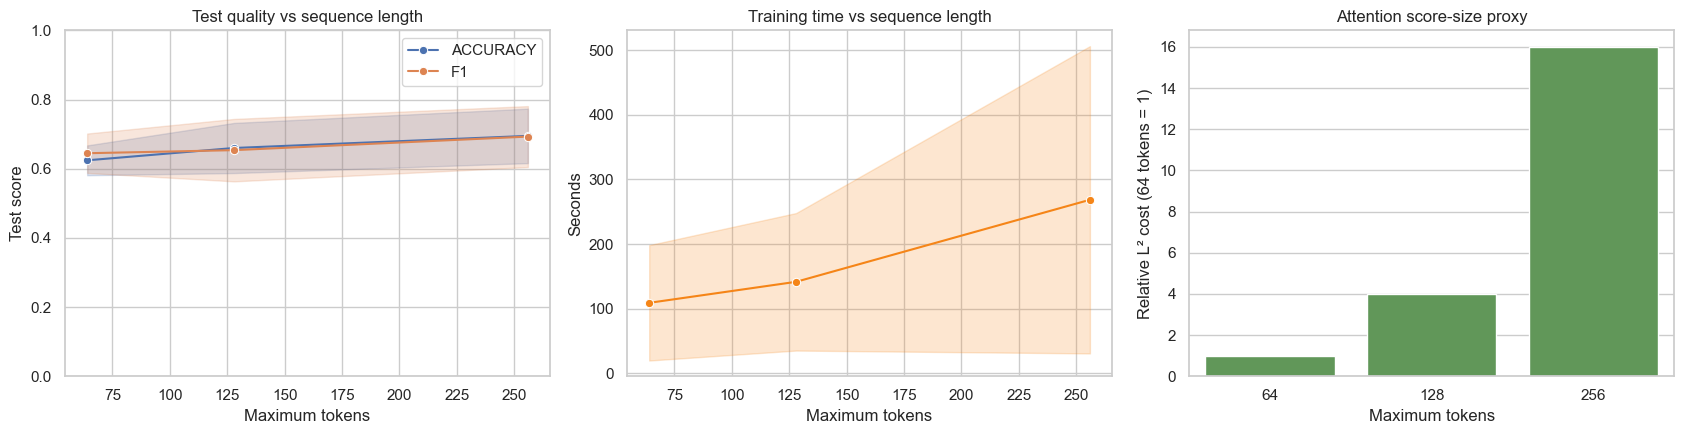

In [29]:
for length in MAX_LENGTHS:
    name=f'17_max_length_{length}'
    row,preds,hist=run_experiment(name,imdb_train,imdb_valid,imdb_test,pretrained=True,max_length=length,epochs=SWEEP_EPOCHS)
    results.append(row); prediction_sets[name]=preds; histories[name]=hist
length_results=pd.DataFrame(results).query("experiment.str.startswith('17_')",engine='python').copy()
length_results['attention_cost_relative_to_64']=(length_results.max_length/64)**2
display(length_results[['experiment','max_length','accuracy','f1','training_seconds','attention_cost_relative_to_64']].round(4))
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for metric in ['accuracy','f1']:
    sns.lineplot(data=length_results,x='max_length',y=metric,marker='o',label=metric.upper(),ax=axes[0])
axes[0].set(title='Test quality vs sequence length',xlabel='Maximum tokens',ylabel='Test score',ylim=(0,1))
sns.lineplot(data=length_results,x='max_length',y='training_seconds',marker='o',ax=axes[1],color='#f58518')
axes[1].set(title='Training time vs sequence length',xlabel='Maximum tokens',ylabel='Seconds')
sns.barplot(data=length_results,x='max_length',y='attention_cost_relative_to_64',color='#59a14f',ax=axes[2])
axes[2].set(title='Attention score-size proxy',xlabel='Maximum tokens',ylabel='Relative L² cost (64 tokens = 1)')
plt.tight_layout(); plt.show()


<!-- codex-analysis-ft-exp17 -->
### Trả lời Experiment 4 — Maximum Sequence Length

Dựa vào log 10 epoch mới nhất trong chính cell này, khi tăng max length từ 64 lên 128 rồi 256, accuracy lần lượt là 0,6675, 0,7325 và 0,7738; F1 là 0,7018, 0,7440 và 0,7811. Thời gian tương ứng là 198,4; 248,0 và 506,1 giây. Tăng 128 lên 256 giúp F1 tăng 3,71 điểm phần trăm nhưng thời gian tăng hơn gấp đôi; độ dài 64 chạy nhanh nhất nhưng bỏ sót nhiều ngữ cảnh hơn.

Có bất nhất cần xử lý trước khi trích bảng cuối: bảng in ngay sau log có thêm các dòng cũ cho cùng tên thí nghiệm (ví dụ length 128 có F1 0,5635), và bảng tổng kết cuối notebook cũng giữ các số liệu cũ của lượt ngắn. Không trộn các dòng đó với log 10 epoch vừa chạy. Các nhận xét trên dùng bộ ba log mới nhất; hãy chạy lại cell tổng kết sau khi làm sạch `results` để bảng và CSV khớp với lượt này.


## 18. Experiment 5 — Domain Shift
Run in-domain references and both transfer directions. Each run selects its checkpoint on source-domain validation data and evaluates on the held-out target-domain test split.


18_imdb_in_domain: initializing pretrained model


18_imdb_in_domain epoch 1/10:   0%|          | 0/150 [00:00<?, ?it/s]

18_imdb_in_domain | epoch 1/10 | train_loss=0.7024 | val_F1=0.6027


18_imdb_in_domain epoch 2/10:   0%|          | 0/150 [00:00<?, ?it/s]

18_imdb_in_domain | epoch 2/10 | train_loss=0.6535 | val_F1=0.6361


18_imdb_in_domain epoch 3/10:   0%|          | 0/150 [00:00<?, ?it/s]

... (72 outputs left out)

18_amazon_to_imdb | epoch 9/10 | train_loss=0.3442 | val_F1=0.8165


18_amazon_to_imdb epoch 10/10:   0%|          | 0/150 [00:00<?, ?it/s]

18_amazon_to_imdb | epoch 10/10 | train_loss=0.3387 | val_F1=0.8180


,experiment,accuracy,f1,roc_auc
11,18_imdb_in_domain,0.7325,0.7440,0.8218
12,18_amazon_in_domain,0.8125,0.8153,0.8908
13,18_imdb_to_amazon,0.7088,0.7203,0.8038
14,18_amazon_to_imdb,0.7000,0.6985,0.7956


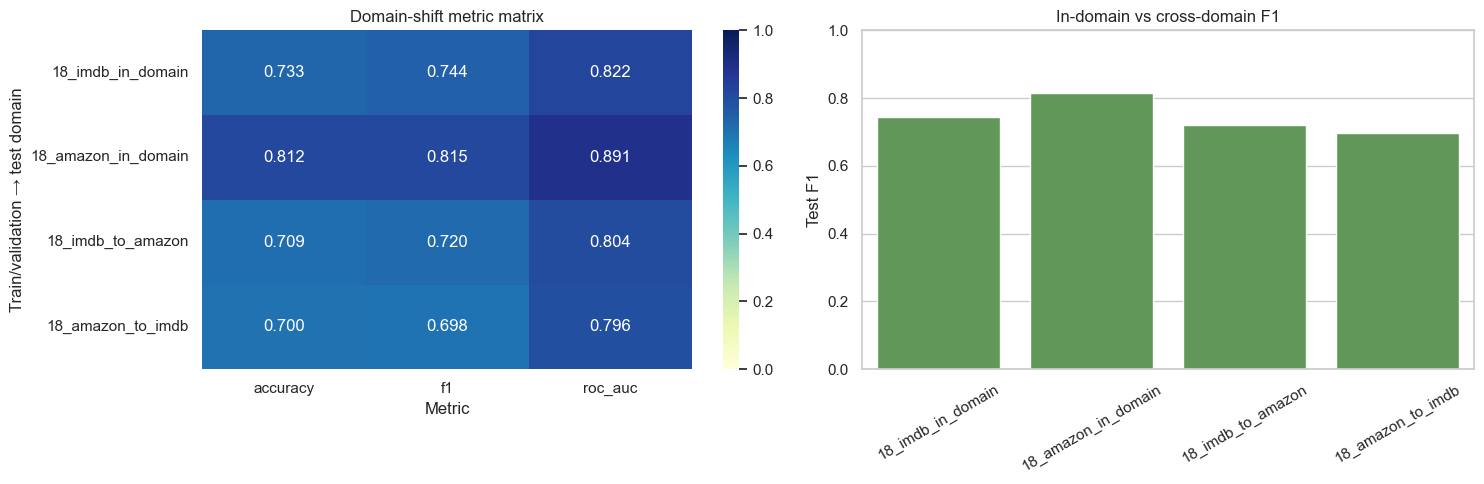

In [22]:
domain_specs=[('18_imdb_in_domain',imdb_train,imdb_valid,imdb_test),
              ('18_amazon_in_domain',amazon_train,amazon_valid,amazon_test),
              ('18_imdb_to_amazon',imdb_train,imdb_valid,amazon_test),
              ('18_amazon_to_imdb',amazon_train,amazon_valid,imdb_test)]
for name,source_train,source_valid,target_test in domain_specs:
    row,preds,hist=run_experiment(name,source_train,source_valid,target_test,pretrained=True)
    results.append(row); prediction_sets[name]=preds; histories[name]=hist
domain_results=pd.DataFrame(results).query("experiment.str.startswith('18_')",engine='python')
display(domain_results[['experiment','accuracy','f1','roc_auc']].round(4))
domain_plot=domain_results.set_index('experiment')[['accuracy','f1','roc_auc']]
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.heatmap(domain_plot,annot=True,fmt='.3f',cmap='YlGnBu',vmin=0,vmax=1,ax=axes[0])
axes[0].set(title='Domain-shift metric matrix',xlabel='Metric',ylabel='Train/validation → test domain')
sns.barplot(data=domain_results,x='experiment',y='f1',color='#59a14f',ax=axes[1])
axes[1].tick_params(axis='x',rotation=30); axes[1].set(title='In-domain vs cross-domain F1',xlabel='',ylabel='Test F1',ylim=(0,1))
plt.tight_layout(); plt.show()

<!-- codex-analysis-ft-exp18 -->
### Trả lời Experiment 5 — Domain Shift

F1 in-domain là 0,7440 khi train/test trên IMDb và 0,8153 trên Amazon. Khi chuyển miền, train IMDb rồi test Amazon đạt F1 0,7203; train Amazon rồi test IMDb đạt 0,6985. So với baseline in-domain của miền đích, F1 giảm khoảng 0,0237 ở chiều IMDb→Amazon và 0,1168 ở chiều Amazon→IMDb. Accuracy của hai lượt chuyển miền lần lượt là 0,7088 và 0,7000.

Quan sát này cho thấy khả năng chuyển miền không hoàn toàn ổn định, đặc biệt ở chiều Amazon→IMDb. Có thể liên quan đến khác biệt về độ dài review (IMDb trung bình 235,7 từ, Amazon 82,6), từ vựng, phong cách đánh giá và phân bố nội dung. Vì độ khó hai tập không giống hệt nhau, không nên quy toàn bộ mức giảm cho riêng một nguyên nhân; kết quả chỉ chứng minh hiệu năng của các cấu hình cross-domain đã thử thấp hơn cấu hình in-domain tương ứng.


## 19. Application — Sentiment Classification
Use the full fine-tuned IMDb classifier as the main application. Report multiple metrics and the confusion matrix; do not infer performance from accuracy alone.

,accuracy,precision,recall,f1,roc_auc,training_seconds
0,0.7325,0.714943,0.775561,0.744019,0.82178,225.323367


,text,true_label,prediction,confidence
113,Many other viewers are saying that this is not...,positive,positive,0.752723
572,"This show is about three little girls. (D.J, S...",positive,positive,0.892189
377,"This is a charming little film, which like man...",positive,positive,0.974093
495,There are only a handful of movies that were m...,positive,positive,0.535514
52,it doesn't matter whether drew or leelee are t...,positive,positive,0.663979


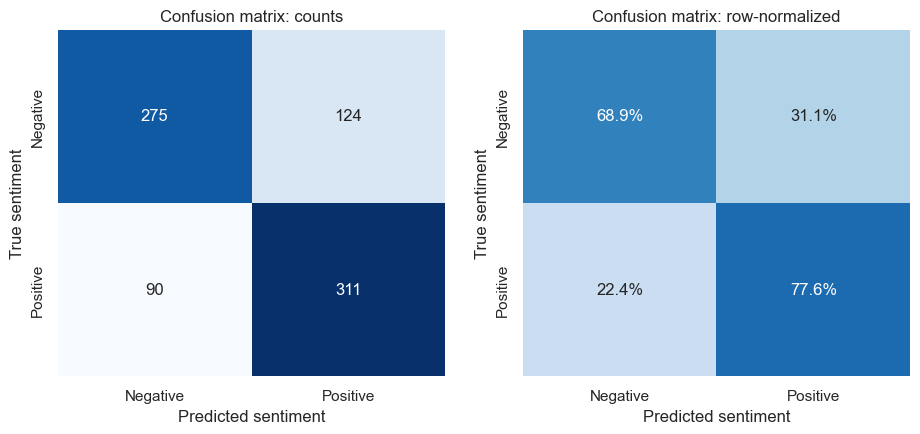

In [23]:
application_name='15_fine_tuning'
application_row=next(r for r in results if r['experiment']==application_name)
application_predictions=prediction_sets[application_name]
display(pd.DataFrame([application_row])[['accuracy','precision','recall','f1','roc_auc','training_seconds']])
cm=np.asarray(application_row['confusion_matrix'])
cm_norm=cm/cm.sum(axis=1,keepdims=True).clip(min=1)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive'],ax=axes[0])
axes[0].set(title='Confusion matrix: counts',xlabel='Predicted sentiment',ylabel='True sentiment')
sns.heatmap(cm_norm,annot=True,fmt='.1%',cmap='Blues',vmin=0,vmax=1,cbar=False,xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive'],ax=axes[1])
axes[1].set(title='Confusion matrix: row-normalized',xlabel='Predicted sentiment',ylabel='True sentiment')
sample_review=application_predictions.sample(5,random_state=SEED).copy()
sample_review['true_label']=sample_review.true_label.map({0:'negative',1:'positive'}); sample_review['prediction']=sample_review.prediction.map({0:'negative',1:'positive'})
display(sample_review[['text','true_label','prediction','confidence']])

<!-- codex-analysis-ft-app -->
### Kết quả Application — Sentiment Classification

Trên 800 review test IMDb, classifier đạt accuracy 0,7325, precision 0,7149, recall 0,7756, F1 0,7440 và ROC-AUC 0,8218. Ma trận nhầm lẫn theo thứ tự nhãn negative, positive là `[[275, 124], [90, 311]]`: đúng 275 negative và 311 positive; nhầm 124 negative thành positive và 90 positive thành negative. Tổng cộng đúng 586/800 review.

Trong năm ví dụ dự đoán đúng được hiển thị, confidence trải từ 0,5355 đến 0,9741. Ví dụ confidence 0,5355 vẫn đúng nhưng khá sát ngưỡng, minh họa rằng một dự đoán đúng không đồng nghĩa model chắc chắn; ngược lại, phần Error Analysis bên dưới có dự đoán sai với confidence rất cao.


## 20. Error Analysis
The cells export examples for your manual categorization. Review false positives, false negatives, and high-confidence mistakes. Assign categories such as negation, sarcasm, long-range dependency, domain-specific expression, rare word, tokenization/context, or label ambiguity; provide your own evidence and hypotheses.

In [24]:
errors=application_predictions.copy()
errors['true_name']=errors.true_label.map({0:'negative',1:'positive'})
errors['pred_name']=errors.prediction.map({0:'negative',1:'positive'})
errors['error_type']=''  # Fill this column after reading each example.
false_positive=errors[(errors.true_label==0)&(errors.prediction==1)].sort_values('confidence',ascending=False)
false_negative=errors[(errors.true_label==1)&(errors.prediction==0)].sort_values('confidence',ascending=False)
high_confidence_wrong=errors[errors.true_label!=errors.prediction].sort_values('confidence',ascending=False)
print('False positives:',len(false_positive),'False negatives:',len(false_negative))
display(false_positive.head(10)[['text','true_name','pred_name','confidence','error_type']])
display(false_negative.head(10)[['text','true_name','pred_name','confidence','error_type']])
display(high_confidence_wrong.head(10)[['text','true_name','pred_name','confidence','error_type']])

False positives: 124 False negatives: 90


,text,true_name,pred_name,confidence,error_type
129,"I saw this movie, just now, not when it was re...",negative,positive,0.961844,
4,Always enjoy great films which deal with the s...,negative,positive,0.960379,
11,One of Frances Farmer's earliest movies; at 22...,negative,positive,0.959684,
310,In short: Spike Lee clearly has a lot on his ...,negative,positive,0.958613,
788,It's hard to believe that in 1997 David Duchov...,negative,positive,0.946294,
261,This is a film that has garnered any interest ...,negative,positive,0.945806,
223,Just watched on UbuWeb this early experimental...,negative,positive,0.943980,
106,Jack Lemmon was one of the finest actors that ...,negative,positive,0.943340,
576,"I've never been a huge fan of Almodovar, but, ...",negative,positive,0.939895,
254,"On assignment in scenic Italy, beautiful lip-s...",negative,positive,0.919818,


,text,true_name,pred_name,confidence,error_type
207,"Honestly, I find this film almost too depressi...",positive,negative,0.974717,
282,"I must say, this movie has given me a dual per...",positive,negative,0.951903,
646,Let me start out by saying I'm a big Carrey fa...,positive,negative,0.945702,
48,"Man, I can't believe the largely harsh and neg...",positive,negative,0.929843,
31,Many mystery stories follow the standard whodu...,positive,negative,0.929632,
158,Paperhouse is the most moving and poignant fil...,positive,negative,0.915514,
157,"Ugh, what an embarrassing episode last night! ...",positive,negative,0.913969,
509,"Man, I think people have forgotten how to watc...",positive,negative,0.912048,
561,A lovely old - fashioned thriller coming on li...,positive,negative,0.900574,
423,Maybe it's just because I have an intense fear...,positive,negative,0.878681,


,text,true_name,pred_name,confidence,error_type
207,"Honestly, I find this film almost too depressi...",positive,negative,0.974717,
129,"I saw this movie, just now, not when it was re...",negative,positive,0.961844,
4,Always enjoy great films which deal with the s...,negative,positive,0.960379,
11,One of Frances Farmer's earliest movies; at 22...,negative,positive,0.959684,
310,In short: Spike Lee clearly has a lot on his ...,negative,positive,0.958613,
282,"I must say, this movie has given me a dual per...",positive,negative,0.951903,
788,It's hard to believe that in 1997 David Duchov...,negative,positive,0.946294,
261,This is a film that has garnered any interest ...,negative,positive,0.945806,
646,Let me start out by saying I'm a big Carrey fa...,positive,negative,0.945702,
223,Just watched on UbuWeb this early experimental...,negative,positive,0.943980,


<!-- codex-analysis-ft-errors -->
### Trả lời Error Analysis bằng các ví dụ trong output

Các ví dụ dưới đây lấy từ bảng false positive/false negative đã in. Confidence là xác suất của nhãn model dự đoán. Phân loại nguyên nhân chỉ là giả thuyết từ phần văn bản đang hiển thị; bảng bị rút gọn bằng dấu `...`, nên cần mở toàn văn trước khi khẳng định loại lỗi.

| True | Pred | Confidence | Đoạn văn hiển thị | Giả thuyết cần kiểm tra |
|---|---|---:|---|---|
| negative | positive | 0,9618 | “I saw this movie, just now, not when it was re...” | Ngữ cảnh/đối lập thời điểm có thể làm tín hiệu cảm xúc mơ hồ |
| negative | positive | 0,9604 | “Always enjoy great films which deal with the s...” | Từ tích cực “enjoy”, “great” có thể lấn át đánh giá tổng thể |
| negative | positive | 0,9597 | “One of Frances Farmer's earliest movies; at 22...” | Cần xem toàn văn; có thể là sentiment phụ thuộc ngữ cảnh phim/nhân vật |
| positive | negative | 0,9747 | “Honestly, I find this film almost too depressi...” | Cảm xúc tiêu cực về nội dung phim có thể không đồng nghĩa đánh giá phim tiêu cực |
| positive | negative | 0,9519 | “I must say, this movie has given me a dual per...” | Tín hiệu trái chiều/ambiguous sentiment có thể gây nhầm |
| positive | negative | 0,9457 | “Let me start out by saying I'm a big Carrey fa...” | Cần đọc phần tiếp theo; có thể có chuyển ý hoặc phụ thuộc ngữ cảnh |

Hai lỗi tự tin nhất trong bảng là false negative 0,9747 và false positive 0,9618. Chúng đáp ứng yêu cầu tìm lỗi confidence cao, nhưng chưa đủ để kết luận là sarcasm, negation hay lỗi nhãn nếu chưa đọc toàn bộ review. Khi nộp, đối chiếu toàn văn và chọn nhãn lỗi phù hợp như ambiguous sentiment, context hoặc label ambiguity; không gán nguyên nhân chỉ từ câu trích bị cắt.


### 20.1. Error pattern visualizations

These plots summarize error counts and confidence. Review individual examples before interpreting why a prediction is wrong.

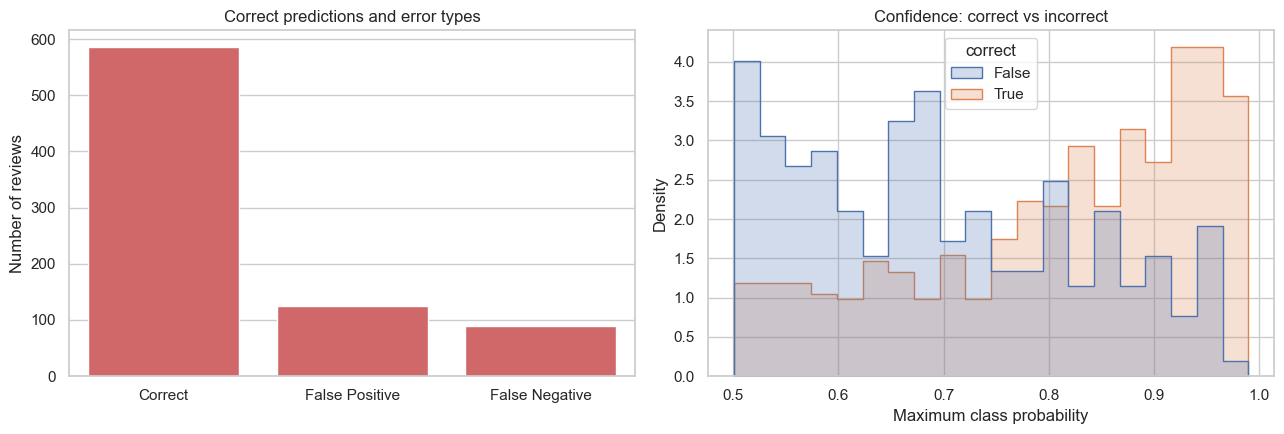

,outcome,reviews
0,Correct,586
1,False Positive,124
2,False Negative,90


In [25]:
errors['error_type']=np.select(
    [(errors.true_label==0)&(errors.prediction==1),(errors.true_label==1)&(errors.prediction==0)],
    ['False Positive','False Negative'],default='Correct')
error_counts=errors.error_type.value_counts().reindex(['Correct','False Positive','False Negative'],fill_value=0).rename_axis('outcome').reset_index(name='reviews')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=error_counts,x='outcome',y='reviews',color='#e15759',ax=axes[0])
axes[0].set(title='Correct predictions and error types',xlabel='',ylabel='Number of reviews')
confidence_errors=errors.copy(); confidence_errors['correct']=confidence_errors.true_label.eq(confidence_errors.prediction)
sns.histplot(data=confidence_errors,x='confidence',hue='correct',bins=20,stat='density',common_norm=False,element='step',ax=axes[1])
axes[1].set(title='Confidence: correct vs incorrect',xlabel='Maximum class probability',ylabel='Density')
plt.tight_layout(); plt.show()
display(error_counts)


<!-- codex-analysis-ft-error-counts -->
### Diễn giải số lượng lỗi

Trong 800 dự đoán, có 586 đúng, 124 false positive và 90 false negative; tổng 214 lỗi, tương đương 26,75% tập test. False positive nhiều hơn false negative 34 trường hợp. Vì vậy model trong lượt này thường nhầm một review negative thành positive hơn chiều ngược lại. Đây là mô tả lỗi trên tập test cụ thể, không phải bằng chứng rằng model luôn thiên lệch positive ở dữ liệu khác.


## 21. Confidence Analysis
Compare confidence distributions for correct/incorrect predictions and inspect calibration by probability bins. Confidence is not a guarantee of correctness.

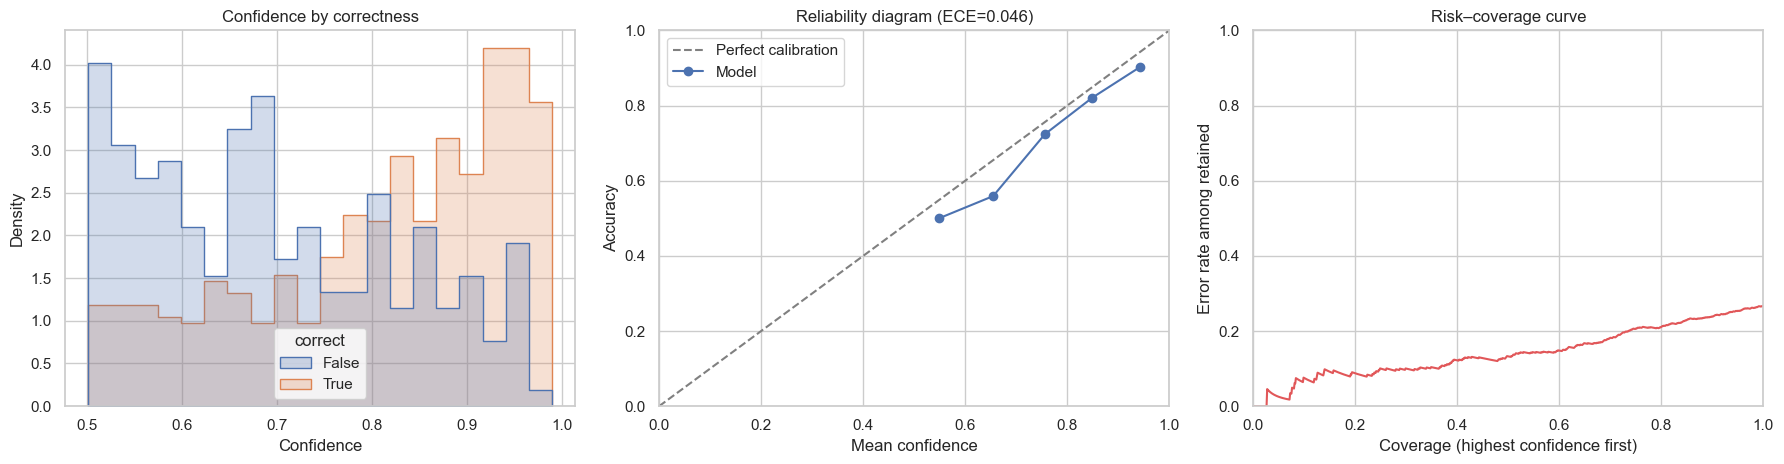

,bin,count,mean_confidence,accuracy
0,"(0.5, 0.6]",134,0.548622,0.500000
1,"(0.6, 0.7]",127,0.654649,0.559055
2,"(0.7, 0.8]",134,0.756156,0.723881
3,"(0.8, 0.9]",179,0.849319,0.821229
4,"(0.9, 1.0]",226,0.942732,0.902655


10-bin expected calibration error: 0.0463


In [26]:
confidence_frame=application_predictions.copy()
confidence_frame['correct']=confidence_frame.true_label.eq(confidence_frame.prediction)
fig,axes=plt.subplots(1,3,figsize=(18,4.8))
sns.histplot(data=confidence_frame,x='confidence',hue='correct',bins=20,stat='density',common_norm=False,element='step',ax=axes[0])
axes[0].set(title='Confidence by correctness',xlabel='Confidence',ylabel='Density')
edges=np.linspace(0,1,11); confidence_frame['bin']=pd.cut(confidence_frame.confidence,edges,include_lowest=True)
calibration=confidence_frame.groupby('bin',observed=False).agg(count=('correct','size'),mean_confidence=('confidence','mean'),accuracy=('correct','mean')).dropna().reset_index()
ece=np.sum(calibration['count']/len(confidence_frame)*np.abs(calibration.accuracy-calibration.mean_confidence))
axes[1].plot([0,1],[0,1],'--',color='gray',label='Perfect calibration')
axes[1].plot(calibration.mean_confidence,calibration.accuracy,'o-',label='Model')
axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean confidence',ylabel='Accuracy',title=f'Reliability diagram (ECE={ece:.3f})'); axes[1].legend()
ranked=confidence_frame.sort_values('confidence',ascending=False).reset_index(drop=True)
ranked['coverage']=np.arange(1,len(ranked)+1)/len(ranked)
ranked['risk']=1-ranked.correct.expanding().mean()
axes[2].plot(ranked.coverage,ranked.risk,color='#e15759')
axes[2].set(xlim=(0,1),ylim=(0,1),xlabel='Coverage (highest confidence first)',ylabel='Error rate among retained',title='Risk–coverage curve')
plt.tight_layout(); plt.show()
display(calibration); print(f'10-bin expected calibration error: {ece:.4f}')


<!-- codex-analysis-ft-confidence -->
### Trả lời Confidence Analysis

Ở nhóm confidence (0,5; 0,6], có 134 dự đoán, confidence trung bình 0,5486 nhưng accuracy chỉ 0,5000. Ở nhóm (0,9; 1,0], có 226 dự đoán, confidence trung bình 0,9427 và accuracy 0,9027; tức khoảng 9,7% nhóm confidence cao vẫn sai. Các nhóm giữa cũng có accuracy thấp hơn confidence trung bình: ví dụ (0,6; 0,7] là 0,5591 so với 0,6546. Trên các bin đã báo cáo, model có xu hướng tự tin hơn mức accuracy thực tế.

ECE 10-bin bằng 0,0463, nghĩa là sai lệch calibration trung bình theo các bin khoảng 4,63 điểm phần trăm theo định nghĩa ECE đã dùng. ECE không phải error rate và không cho biết loại review nào sai. Confidence có ích để xếp mức rủi ro, nhưng không thể xem là xác suất chắc chắn đúng cho từng review.


## 22. Ablation / Analysis
Compare controlled experiment rows. Use observations → numerical evidence → your interpretation in the report. This cell visualizes the collected runs without generating a written conclusion.

,experiment,train_rows,max_length,accuracy,precision,recall,f1,roc_auc,training_seconds
0,14_pretrained,2400,128,0.7325,0.7149,0.7756,0.7440,0.8218,314.9447
1,14_from_scratch,2400,128,0.5938,0.5586,0.9027,0.6902,0.7085,303.1411
2,15_feature_extraction,2400,128,0.6888,0.6818,0.7107,0.6960,0.7679,75.1726
3,15_fine_tuning,2400,128,0.7325,0.7149,0.7756,0.7440,0.8218,225.3234
4,16_train_10pct,240,128,0.5325,0.5278,0.6384,0.5779,0.5493,4.0758
5,16_train_25pct,600,128,0.5512,0.5669,0.4439,0.4979,0.5692,7.0391
6,16_train_50pct,1200,128,0.5688,0.5686,0.5786,0.5735,0.5980,15.2098
7,16_train_100pct,2400,128,0.5875,0.6000,0.5312,0.5635,0.6395,27.2086
8,17_max_length_64,2400,64,0.5812,0.5801,0.5960,0.5879,0.6141,20.0381
9,17_max_length_128,2400,128,0.5875,0.6000,0.5312,0.5635,0.6395,35.4469


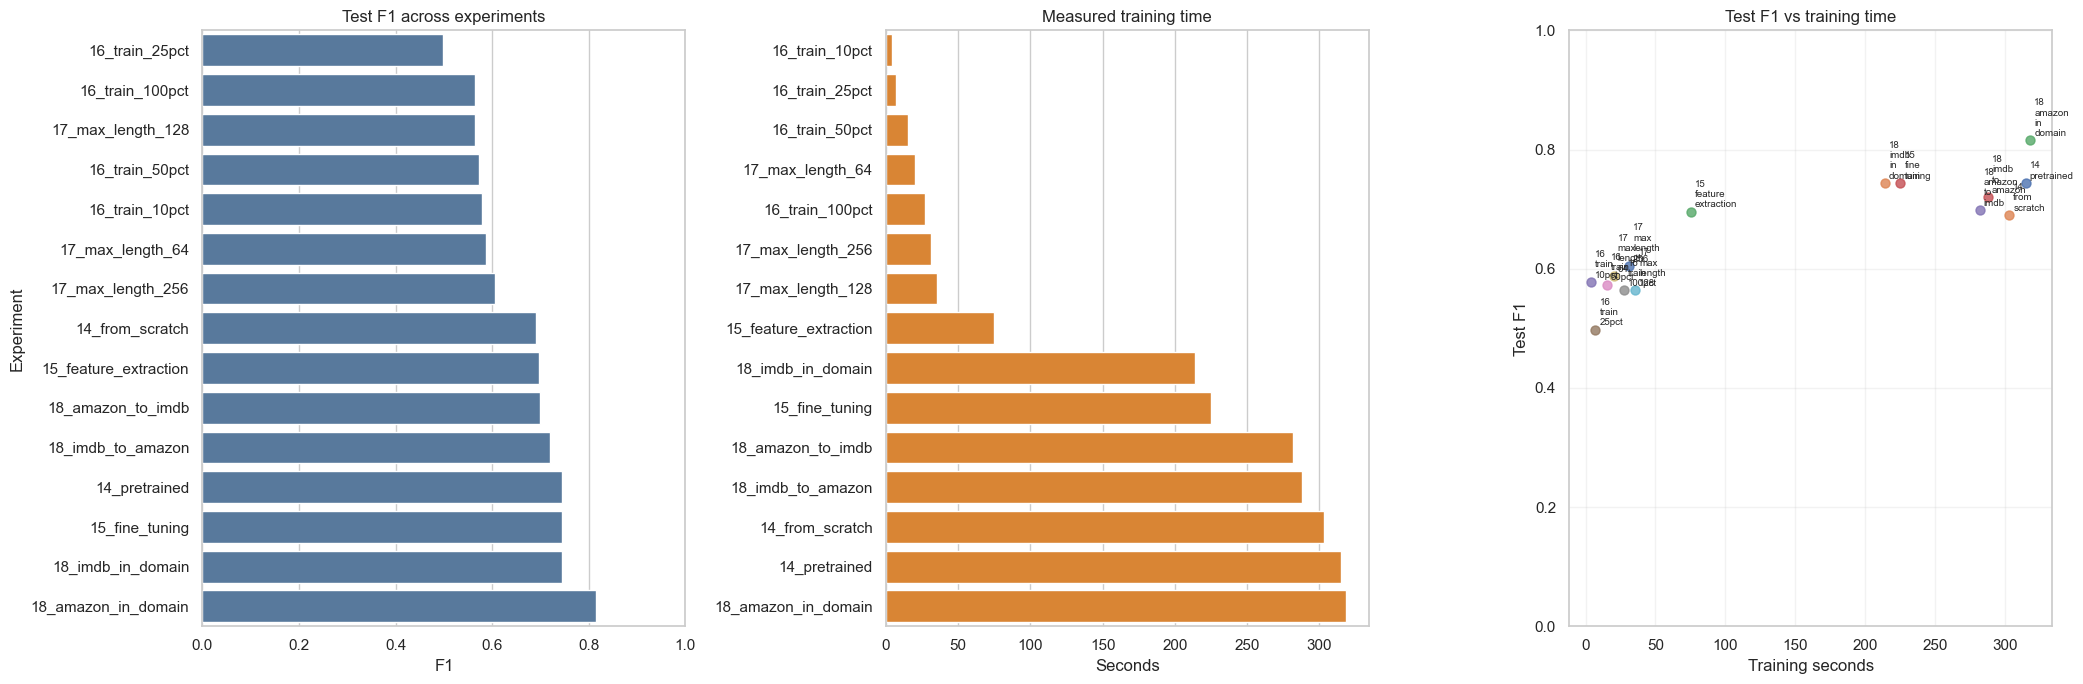

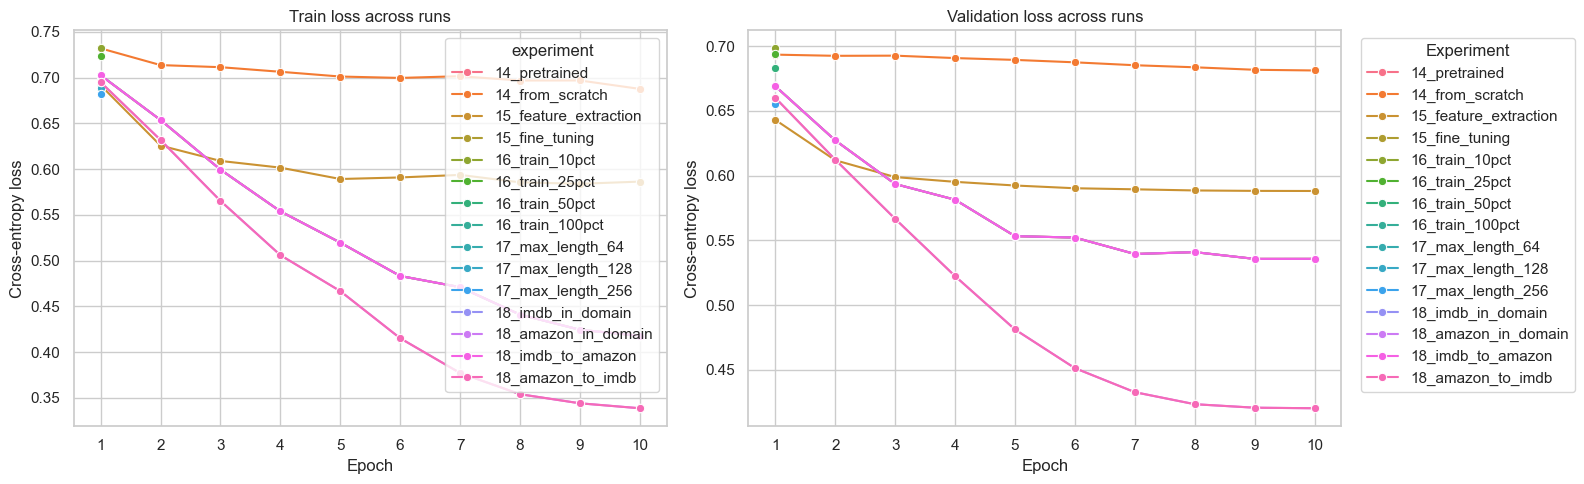

In [27]:
results_df=pd.DataFrame(results)
display(results_df[['experiment','train_rows','max_length','accuracy','precision','recall','f1','roc_auc','training_seconds']].round(4))
fig,axes=plt.subplots(1,3,figsize=(21,7))
quality=results_df.sort_values('f1')
sns.barplot(data=quality,x='f1',y='experiment',color='#4c78a8',ax=axes[0])
axes[0].set(title='Test F1 across experiments',xlabel='F1',ylabel='Experiment',xlim=(0,1))
runtime=results_df.sort_values('training_seconds')
sns.barplot(data=runtime,x='training_seconds',y='experiment',color='#f58518',ax=axes[1])
axes[1].set(title='Measured training time',xlabel='Seconds',ylabel='')
for _,row in results_df.iterrows():
    axes[2].scatter(row.training_seconds,row.f1,s=42,alpha=.8)
    axes[2].annotate(row.experiment.replace('_','\n'),(row.training_seconds,row.f1),fontsize=7,xytext=(3,3),textcoords='offset points')
axes[2].set(title='Test F1 vs training time',xlabel='Training seconds',ylabel='Test F1',ylim=(0,1)); axes[2].grid(alpha=.25)
plt.tight_layout(); plt.show()

all_curve_rows=[]
for run_name,points in histories.items():
    for point in points:
        all_curve_rows.extend([
            {'experiment':run_name,'epoch':point['epoch'],'split':'Train','loss':point['train_loss']},
            {'experiment':run_name,'epoch':point['epoch'],'split':'Validation','loss':point['loss']},
        ])
all_curves=pd.DataFrame(all_curve_rows)
if not all_curves.empty:
    fig,axes=plt.subplots(1,2,figsize=(16,5))
    for split,ax in [('Train',axes[0]),('Validation',axes[1])]:
        view=all_curves[all_curves.split==split]
        sns.lineplot(data=view,x='epoch',y='loss',hue='experiment',marker='o',ax=ax)
        ax.set(title=f'{split} loss across runs',xlabel='Epoch',ylabel='Cross-entropy loss',xticks=sorted(view.epoch.unique()))
    axes[1].legend(title='Experiment',bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout(); plt.show()


<!-- codex-analysis-ft-ablation -->
### Tổng hợp Ablation / Analysis theo output

Quan sát chính: (1) pretrained vượt scratch trên IMDb test: F1 0,7440 so với 0,6902; (2) fine-tuning vượt frozen encoder: F1 0,7440 so với 0,6960, đổi lại thời gian tăng từ 75,2 lên 225,3 giây; (3) tăng dữ liệu làm accuracy/ROC-AUC của lượt quét 1 epoch tăng nhìn chung, nhưng F1 không đơn điệu; (4) log mới nhất cho thấy length 256 đạt F1 cao nhất 0,7811 nhưng mất 506,1 giây; (5) cross-domain thấp hơn in-domain, rõ nhất ở Amazon→IMDb.

Giới hạn cần ghi trong báo cáo: data-efficiency chỉ chạy pretrained và một epoch nên không trả lời so sánh pretrained/scratch ở ít dữ liệu; sequence-length có output cũ và mới trùng tên, cần làm sạch rồi chạy lại bảng tổng kết/CSV. Các kết quả là bằng chứng cho những split, model BERT-Tiny và ngân sách CPU cụ thể, không đủ để khái quát cho mọi Transformer.


In [30]:
# SAVE FOUR DELIVERABLES: data efficiency, confusion matrix, confidence analysis, and all results
from pathlib import Path

# Save beside this notebook when run locally; in Colab, save in the current lab folder.
OUTPUT_DIR = Path.cwd()
LOCAL_LAB08 = Path(r'D:/Study/Study_Class/Semester_7/NLP/Lab/lab08')
if LOCAL_LAB08.exists():
    OUTPUT_DIR = LOCAL_LAB08
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1) Data-efficiency plot: quality and runtime by training-set size.
efficiency_export = pd.DataFrame([r for r in results if str(r['experiment']).startswith('16_')])
efficiency_export = efficiency_export.drop_duplicates('training_fraction', keep='last').sort_values('training_fraction')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for metric in ['accuracy', 'f1']:
    sns.lineplot(data=efficiency_export, x='training_fraction', y=metric,
                 marker='o', label=metric.upper(), ax=axes[0])
axes[0].set(title='Data efficiency: test quality', xlabel='Fraction of training data',
            ylabel='Test score', ylim=(0, 1))
sns.barplot(data=efficiency_export, x='training_fraction', y='training_seconds',
            color='#f58518', ax=axes[1])
axes[1].set(title='Training time by data amount', xlabel='Fraction of training data',
            ylabel='Seconds')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'data_efficiency.png', dpi=180, bbox_inches='tight')
plt.close(fig)

# 2) Confusion matrix for the main IMDb application (fine-tuned model).
cm = np.asarray(application_row['confusion_matrix'])
cm_normalized = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'], ax=axes[0])
axes[0].set(title='Confusion matrix — counts', xlabel='Predicted', ylabel='True')
sns.heatmap(cm_normalized, annot=True, fmt='.1%', cmap='Blues', vmin=0, vmax=1,
            cbar=False, xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'], ax=axes[1])
axes[1].set(title='Confusion matrix — row normalized', xlabel='Predicted', ylabel='True')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.close(fig)

# 3) Confidence distribution, reliability diagram, and risk-coverage curve.
confidence_export = application_predictions.copy()
confidence_export['correct'] = confidence_export.true_label.eq(confidence_export.prediction)
confidence_export['confidence'] = confidence_export.confidence.astype(float)
bin_edges = np.linspace(0, 1, 11)
confidence_export['confidence_bin'] = pd.cut(confidence_export.confidence, bin_edges, include_lowest=True)
calibration_export = confidence_export.groupby('confidence_bin', observed=False).agg(
    count=('correct', 'size'), mean_confidence=('confidence', 'mean'),
    accuracy=('correct', 'mean')).dropna().reset_index()
ece_export = np.sum(calibration_export['count'] / len(confidence_export) *
                    np.abs(calibration_export.accuracy - calibration_export.mean_confidence))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data=confidence_export, x='confidence', hue='correct', bins=20,
             stat='density', common_norm=False, element='step', ax=axes[0])
axes[0].set(title='Confidence by correctness', xlabel='Confidence', ylabel='Density')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
axes[1].plot(calibration_export.mean_confidence, calibration_export.accuracy,
             'o-', label='Model')
axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean confidence', ylabel='Accuracy',
            title=f'Reliability diagram (ECE={ece_export:.3f})')
axes[1].legend()
ranked_export = confidence_export.sort_values('confidence', ascending=False).reset_index(drop=True)
ranked_export['coverage'] = np.arange(1, len(ranked_export) + 1) / len(ranked_export)
ranked_export['risk'] = 1 - ranked_export.correct.expanding().mean()
axes[2].plot(ranked_export.coverage, ranked_export.risk, color='#e15759')
axes[2].set(xlim=(0, 1), ylim=(0, 1), xlabel='Coverage, highest confidence first',
            ylabel='Error rate', title='Risk–coverage curve')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confidence_analysis.png', dpi=180, bbox_inches='tight')
plt.close(fig)

# 4) One row per experiment, keeping the latest run if a cell was executed repeatedly.
results_export = pd.DataFrame(results).drop_duplicates(subset='experiment', keep='last')
application_export = application_row.copy()
application_export['experiment'] = '19_application_sentiment_classification'
application_export['condition'] = 'Fine-tuned IMDb application'
results_export = pd.concat([results_export, pd.DataFrame([application_export])], ignore_index=True)
results_export.to_csv(OUTPUT_DIR / 'results.csv', index=False, encoding='utf-8-sig')

print('Saved files:')
for filename in ['data_efficiency.png', 'confusion_matrix.png', 'confidence_analysis.png', 'results.csv']:
    print(' -', OUTPUT_DIR / filename)


Saved files:
 - D:\Study\Study_Class\Semester_7\NLP\Lab\lab08\data_efficiency.png
 - D:\Study\Study_Class\Semester_7\NLP\Lab\lab08\confusion_matrix.png
 - D:\Study\Study_Class\Semester_7\NLP\Lab\lab08\confidence_analysis.png
 - D:\Study\Study_Class\Semester_7\NLP\Lab\lab08\results.csv
